# Laya financial NLP: fine-tune, infer, and benchmark

This Kaggle notebook fine-tunes the open-weight **Laya** typed-decision model on your financial benchmark CSVs, then compares the base and fine-tuned checkpoints on held-out examples for:

1. Sentiment classification (PhraseBank and Twitter Financial News)
2. Sentiment regression (-1 to +1; FiQA)
3. Multi-label ticker prediction (Financial News Ticker Linking)

The training cell adapts Laya's upstream RLCD recipe: typed decision records, a proper-scoring reward, soft-label cross-entropy guidance, and validation-only temperature calibration. The test split is reserved for final scores. Fine-tuning is optional: set `RUN_FINETUNING = False` to benchmark the base checkpoint only or reuse an existing fine-tuned directory.

**Kaggle setup:** attach the benchmark dataset as an input; enable Internet and a GPU (a T4 is recommended) so Laya can download its pretrained weights and train. Outputs go to `/kaggle/working/laya_financial_benchmark/`. The starter limits intentionally keep fine-tuning and inference manageable; increase them after a short run succeeds.

Upstream source: [Laya GitHub README](https://github.com/NandhaKishorM/laya) and [the authors' Kaggle RLCD fine-tuning notebook](https://github.com/NandhaKishorM/laya/blob/main/notebooks/laya_finetune_typed_decisions_2xT4_kaggle.ipynb).


## 1. Install dependencies and check the Kaggle GPU

In [1]:
%pip -q install -U "laya>=0.3.24" safetensors huggingface_hub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.6/106.6 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 298.9/298.9 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 25.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import ast, json, os, random, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
    hamming_loss, average_precision_score)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU accelerator before running the training and inference cells.")
DEVICE = "cuda"
print("GPU:", torch.cuda.get_device_name(0), "| PyTorch:", torch.__version__)

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/laya_financial_benchmark")
MODEL_DIR = OUTPUT_DIR / "laya_financial_finetuned"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Start modestly; set a limit to None for the full corresponding split.
CLASSIFICATION_TRAIN_LIMIT = 1200
REGRESSION_TRAIN_LIMIT = 800
TICKER_TRAIN_ARTICLE_LIMIT = 50
CLASSIFICATION_TEST_LIMIT = 300
REGRESSION_TEST_LIMIT = 300
TICKER_VALIDATION_LIMIT = 50
TICKER_TEST_LIMIT = 100
INFERENCE_BATCH_SIZE = 8

RUN_FINETUNING = True
USE_EXISTING_FINETUNED_MODEL = False
EPOCHS = 12
MICRO_BATCH_SIZE = 2
GRADIENT_ACCUMULATION = 8
RLCD_GROUP_SIZE = 4
LR_ENCODER = 2.0e-5
LR_HEAD = 8.0e-5


GPU: Tesla T4 | PyTorch: 2.11.0+cu128


## 2. Locate and inspect the benchmark CSVs

In [3]:
def find_csv(filename):
    matches = list(INPUT_ROOT.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Attach the benchmark dataset containing {filename} to this Kaggle notebook.")
    return matches[0]

PATHS = {
    "phrasebank": find_csv("financial_phrasebank_50agree.csv"),
    "twitter": find_csv("twitter_financial_news_sentiment.csv"),
    "fiqa": find_csv("fiqa_2018_sentiment_regression.csv"),
    "ticker": find_csv("financial_news_ticker_linking.csv"),
}
for name, path in PATHS.items(): print(f"{name}: {path}")


phrasebank: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_phrasebank_dataset/financial_phrasebank_50agree.csv
twitter: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/twitter_financial_news_sentiment.csv
fiqa: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/fiqa_2018_sentiment_regression.csv
ticker: /kaggle/input/datasets/arjunverma14142/finance-dataset/benchmarks/financial_news_ticker_linking.csv


## 3. Build leakage-aware splits and typed decision examples

In [4]:
LABELS = ["negative", "neutral", "positive"]
CLASS_CRITERIA = {
    "negative": "Financially negative or bearish outlook for the company, asset, or market.",
    "neutral": "Factual, mixed, or no clear positive or negative financial sentiment.",
    "positive": "Financially positive or bullish outlook for the company, asset, or market."
}
SCORE_VALUES = np.linspace(-1.0, 1.0, 11)
SCORE_CRITERIA = [f"Overall financial sentiment {v:+.1f} (-1 very negative, +1 very positive)." for v in SCORE_VALUES]
TICKERS = ["AAPL","MSFT","GOOGL","AMZN","NVDA","META","TSLA","BRK.B","JPM","V","JNJ","WMT","PG","MA","HD","XOM","CVX","LLY","ABBV","MRK","BAC","KO","PEP","COST","AVGO","ORCL","ADBE","CRM","NFLX","AMD","INTC","CSCO","QCOM","TXN","IBM","DIS","NKE","MCD","T","PFE","UNH","CAT","GE","BA","GS","C","WFC","PYPL","UBER"]

def norm_label(x):
    x=str(x).strip().lower()
    return {"bearish":"negative", "bullish":"positive", "neg":"negative", "neu":"neutral", "pos":"positive"}.get(x,x)

def split_train_validation(frame, label_col=None, test_size=.1):
    if label_col and frame[label_col].nunique()>1:
        train, val = train_test_split(frame, test_size=test_size, random_state=SEED, stratify=frame[label_col])
    else:
        train, val = train_test_split(frame, test_size=test_size, random_state=SEED)
    return train.reset_index(drop=True), val.reset_index(drop=True)

def apply_limit(frame, limit):
    if limit is None or len(frame)<=limit: return frame.reset_index(drop=True)
    return frame.sample(n=limit, random_state=SEED).reset_index(drop=True)

def classification_split(dataset):
    df=pd.read_csv(PATHS[dataset]).dropna(subset=["text","label"]).copy()
    df["text"]=df.text.astype(str); df["label"]=df.label.map(norm_label)
    df=df[df.label.isin(LABELS)].drop_duplicates("text").reset_index(drop=True)
    if dataset=="twitter" and "split" in df and df.split.astype(str).str.lower().eq("test").any():
        test=df[df.split.astype(str).str.lower().eq("test")].copy()
        trainval=df[~df.split.astype(str).str.lower().eq("test")].copy()
        train,val=split_train_validation(trainval,"label")
    else:
        trainval,test=train_test_split(df,test_size=.1,random_state=SEED,stratify=df.label)
        train,val=split_train_validation(trainval,"label",test_size=1/9)
    return train.reset_index(drop=True),val.reset_index(drop=True),test.reset_index(drop=True)

CLASS_DATA={name:classification_split(name) for name in ["phrasebank","twitter"]}
for name,(tr,va,te) in CLASS_DATA.items(): print(name, "train/val/test:",len(tr),len(va),len(te),"train labels:",tr.label.value_counts().to_dict())

fiqa=pd.read_csv(PATHS["fiqa"]).dropna(subset=["sentence","sentiment_score"]).copy()
fiqa["sentiment_score"]=pd.to_numeric(fiqa.sentiment_score,errors="coerce")
fiqa=fiqa.dropna(subset=["sentiment_score"]); fiqa.sentiment_score=fiqa.sentiment_score.clip(-1,1)
if "split" in fiqa and fiqa.split.astype(str).str.lower().eq("test").any():
    fiqa_test=fiqa[fiqa.split.astype(str).str.lower().eq("test")].copy()
    fiqa_trainval=fiqa[~fiqa.split.astype(str).str.lower().eq("test")].copy()
    fiqa_train,fiqa_val=split_train_validation(fiqa_trainval)
else:
    fiqa_trainval,fiqa_test=train_test_split(fiqa,test_size=.2,random_state=SEED)
    fiqa_train,fiqa_val=split_train_validation(fiqa_trainval)
fiqa_train,fiqa_val,fiqa_test=[x.reset_index(drop=True) for x in [fiqa_train,fiqa_val,fiqa_test]]
print("FiQA train/val/test:",len(fiqa_train),len(fiqa_val),len(fiqa_test))

def parse_tickers(value):
    try: value=json.loads(value) if isinstance(value,str) else value
    except Exception:
        try: value=ast.literal_eval(value)
        except Exception: value=[]
    if not isinstance(value,(list,tuple,set)): value=[value] if value else []
    return sorted({str(x).strip().upper().replace("$","") for x in value if str(x).strip()})

ticker=pd.read_csv(PATHS["ticker"],usecols=["text","title","date_publish","url","mentioned_companies"],low_memory=False)
ticker=ticker.dropna(subset=["mentioned_companies"])
ticker["text"]=ticker.text.fillna("").astype(str); ticker["title"]=ticker.title.fillna("").astype(str)
ticker["url"]=ticker.url.fillna("").astype(str)
ticker["_norm"]=ticker.text.str.lower().str.replace(r"\s+"," ",regex=True).str.strip()
ticker=ticker[ticker._norm.ne("")]
if ticker.url.ne("").any(): ticker=ticker.drop_duplicates("url")
ticker=ticker.drop_duplicates("_norm").reset_index(drop=True)
ticker["gold_tickers"]=ticker.mentioned_companies.map(parse_tickers)
ticker["_date"]=pd.to_datetime(ticker.date_publish,errors="coerce",utc=True)
ticker=ticker.sort_values("_date",na_position="first").reset_index(drop=True)
has_label=ticker.gold_tickers.map(lambda xs: bool(set(xs)&set(TICKERS)))
ticker=ticker[has_label].reset_index(drop=True)
split_a=int(len(ticker)*.70); split_b=int(len(ticker)*.85)
ticker_train=ticker.iloc[:split_a].copy(); ticker_val=ticker.iloc[split_a:split_b].copy(); ticker_test=ticker.iloc[split_b:].copy()
ticker_train=apply_limit(ticker_train,TICKER_TRAIN_ARTICLE_LIMIT)
ticker_val=apply_limit(ticker_val,TICKER_VALIDATION_LIMIT)
ticker_test=apply_limit(ticker_test,TICKER_TEST_LIMIT)
print("Ticker articles train/val/test:",len(ticker_train),len(ticker_val),len(ticker_test))


phrasebank train/val/test: 3870 484 484 train labels: {'neutral': 2298, 'positive': 1090, 'negative': 482}
twitter train/val/test: 9544 1193 1194 train labels: {'neutral': 6195, 'positive': 1918, 'negative': 1431}
FiQA train/val/test: 956 107 150
Ticker articles train/val/test: 50 50 100


## 4. Convert labeled examples into Laya decision records

Classification uses `choice`, FiQA regression uses an 11-level ordered `score` rubric mapped to the continuous target, and ticker linking uses one `noul` decision per (article, ticker) during training. For ticker training, all positives are retained and at most five negative ticker pairs per positive are sampled; validation/test still evaluate the complete ticker set. This limits the extreme negative-label imbalance without leaking test examples into training.


In [5]:
def state_for_class(row): return str(row.text)[:2500]
def class_question(): return {"type":"choice","instructions":"Classify the overall sentiment toward the financial company, security, or market described in the text.","criteria":CLASS_CRITERIA}
def state_for_fiqa(row):
    target=str(row.get("target", "")).strip()
    return f"Target: {target}\nText: {str(row.sentence)[:2500]}"
def regression_question(): return {"type":"score","instructions":"Rate the overall financial sentiment toward the stated target. Negative values mean bearish/negative, zero means neutral or mixed, and positive values mean bullish/positive.","criteria":SCORE_CRITERIA}
def state_for_ticker(row): return (str(row.title)+"\n\n"+str(row.text))[:2500]
def ticker_question(symbol):
    return {"type":"noul","instructions":f"Does this article explicitly discuss {symbol} as a relevant company or security? Ignore unrelated incidental mentions.","criteria":{"true":f"The article explicitly discusses {symbol}.","false":f"The article does not discuss {symbol}."}}

def one_hot(n,idx):
    x=np.zeros(n,dtype=np.float32); x[idx]=1.; return x.tolist()

def score_distribution(value):
    pos=float(np.clip((float(value)+1.0)/2.0*(len(SCORE_VALUES)-1),0,len(SCORE_VALUES)-1))
    lo=int(np.floor(pos)); hi=min(lo+1,len(SCORE_VALUES)-1); frac=pos-lo
    out=np.zeros(len(SCORE_VALUES),dtype=np.float32); out[lo]+=1-frac; out[hi]+=frac
    return out.tolist()

train_records=[]; calibration_records=[]
for dataset,(train_df,val_df,_) in CLASS_DATA.items():
    train_df=apply_limit(train_df,CLASSIFICATION_TRAIN_LIMIT)
    for _,r in train_df.iterrows():
        train_records.append({"state":state_for_class(r),"question":class_question(),"target":one_hot(3,LABELS.index(r.label)),"task":"classification"})
    for _,r in val_df.iterrows():
        calibration_records.append({"state":state_for_class(r),"question":class_question(),"target":one_hot(3,LABELS.index(r.label)),"task":"classification"})

fiqa_train_sample=apply_limit(fiqa_train,REGRESSION_TRAIN_LIMIT)
for _,r in fiqa_train_sample.iterrows():
    train_records.append({"state":state_for_fiqa(r),"question":regression_question(),"target":score_distribution(r.sentiment_score),"task":"regression"})
for _,r in fiqa_val.iterrows():
    calibration_records.append({"state":state_for_fiqa(r),"question":regression_question(),"target":score_distribution(r.sentiment_score),"task":"regression"})

for _,r in ticker_train.iterrows():
    positives=sorted(set(r.gold_tickers)&set(TICKERS))
    negatives=[s for s in TICKERS if s not in positives]
    if not positives: continue
    rng=random.Random(SEED+int(r.name))
    sampled_negatives=rng.sample(negatives,min(len(negatives),5*len(positives)))
    state=state_for_ticker(r)
    for symbol in positives+sampled_negatives:
        is_positive=int(symbol in positives)
        train_records.append({"state":state,"question":ticker_question(symbol),"target":one_hot(2,1 if is_positive else 0),"task":"ticker"})
for _,r in ticker_val.iterrows():
    state=state_for_ticker(r)
    for symbol in TICKERS:
        is_positive=int(symbol in set(r.gold_tickers))
        calibration_records.append({"state":state,"question":ticker_question(symbol),"target":one_hot(2,1 if is_positive else 0),"task":"ticker"})

print("Training decisions:",len(train_records),pd.Series([x["task"] for x in train_records]).value_counts().to_dict())
print("Calibration decisions:",len(calibration_records))
if RUN_FINETUNING and len(train_records)<100:
    raise ValueError("Too few training decisions were built. Check the input CSVs and label mappings.")


Training decisions: 3620 {'classification': 2400, 'regression': 800, 'ticker': 420}
Calibration decisions: 4234


## 5. Download the base Laya checkpoint and prepare training items

In [6]:
import laya
from huggingface_hub import snapshot_download
from safetensors.torch import load_file, save_file
from transformers import AutoTokenizer
from laya.agent import _fix_tokenizer_config
from laya.common import build_sequence, render_options, QTYPES, build_model, proper_reward, TEMP_MIN, TEMP_MAX

BASE_MODEL_ID="convaiinnovations/laya"
BASE_MODEL_DIR=snapshot_download(BASE_MODEL_ID)
_fix_tokenizer_config(BASE_MODEL_DIR)
with open(Path(BASE_MODEL_DIR)/"rl_agent_config.json",encoding="utf-8") as f: BASE_CONFIG=json.load(f)
TOKENIZER=AutoTokenizer.from_pretrained(Path(BASE_MODEL_DIR)/"tokenizer")
BASE_CONFIG["max_len"]=512
BASE_CONFIG["head_max_len"]=192
BASE_CONFIG["gradient_checkpointing"]=True

def make_item(record):
    q=record["question"]
    qtype={"t":q["type"],"ins":q["instructions"],"crit":q.get("criteria",{})}
    seq,markers=build_sequence(TOKENIZER,record["state"],qtype,BASE_CONFIG["max_len"],BASE_CONFIG["head_max_len"])
    expected=len(render_options(qtype))
    if len(markers)!=expected: return None
    target=record["target"]
    if len(target)!=expected: raise ValueError(f"Target has {len(target)} levels but question renders {expected} options")
    return {"ids":seq,"markers":markers,"qtype":QTYPES[q["type"]],"target":target,"label":int(np.argmax(target))}

if RUN_FINETUNING:
    train_items=[x for rec in tqdm(train_records,desc="Tokenize train decisions") if (x:=make_item(rec)) is not None]
    calibration_items=[x for rec in tqdm(calibration_records,desc="Tokenize calibration decisions") if (x:=make_item(rec)) is not None]
    print("Tokenized train/calibration:",len(train_items),len(calibration_items))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 38 files:   0%|          | 0/38 [00:00<?, ?it/s]

Tokenize train decisions:   0%|          | 0/3620 [00:00<?, ?it/s]

Tokenize calibration decisions:   0%|          | 0/4234 [00:00<?, ?it/s]

Tokenized train/calibration: 3620 4234


## 6. Fine-tune with RLCD on the Kaggle GPU

The optimization follows the upstream recipe's core: draw small perturbations around each decision's logits, compare sampled distributions to the gold soft targets with Laya's proper-scoring reward, and combine the policy-gradient signal with cross-entropy guidance. Encoder and decision-head learning rates are separate. Each epoch saves a recoverable checkpoint; validation decisions are held out for per-question-type temperature fitting.


In [7]:
def collate_items(items,pad_id):
    n=len(items); length=max(len(x["ids"]) for x in items); kmax=max(len(x["markers"]) for x in items)
    ids=torch.full((n,length),pad_id,dtype=torch.long); att=torch.zeros((n,length),dtype=torch.long)
    mpos=torch.zeros((n,kmax),dtype=torch.long); mmask=torch.zeros((n,kmax),dtype=torch.bool)
    target=torch.zeros((n,kmax),dtype=torch.float32)
    for i,it in enumerate(items):
        ids[i,:len(it["ids"])]=torch.tensor(it["ids"]); att[i,:len(it["ids"])]=1
        k=len(it["markers"]); mpos[i,:k]=torch.tensor(it["markers"]); mmask[i,:k]=True
        target[i,:len(it["target"])]=torch.tensor(it["target"],dtype=torch.float32)
    return ids,att,mpos,mmask,target,torch.tensor([x["qtype"] for x in items])

def fit_temperature(rows):
    if len(rows)<10: return 1.0
    kmax=max(len(z) for z,t in rows); z=torch.full((len(rows),kmax),-1e4); target=torch.zeros((len(rows),kmax))
    for i,(logits,dist) in enumerate(rows):
        z[i,:len(logits)]=torch.as_tensor(logits); target[i,:len(dist)]=torch.as_tensor(dist)
    log_t=torch.zeros(1,requires_grad=True); opt=torch.optim.LBFGS([log_t],lr=.1,max_iter=80)
    def closure():
        opt.zero_grad(); loss=-(target*torch.log_softmax(z/log_t.exp(),dim=-1)).sum(-1).mean(); loss.backward(); return loss
    opt.step(closure)
    return float(torch.clamp(log_t.exp(),TEMP_MIN,TEMP_MAX).item())

if RUN_FINETUNING:
    cfg=dict(BASE_CONFIG)
    model=build_model(cfg,encoder_dir=str(Path(BASE_MODEL_DIR)/"encoder"))
    model.load_state_dict(load_file(str(Path(BASE_MODEL_DIR)/"model.safetensors")),strict=True)
    if hasattr(model.encoder,"gradient_checkpointing_enable"):
        model.encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant":False})
    model.head_checkpointing=True
    model.to(DEVICE).train()
    enc_params=[p for n,p in model.named_parameters() if "encoder." in n]
    head_params=[p for n,p in model.named_parameters() if "encoder." not in n]
    optimizer=torch.optim.AdamW([{"params":enc_params,"lr":LR_ENCODER},{"params":head_params,"lr":LR_HEAD}],weight_decay=.01)
    steps=max(1,(len(train_items)//MICRO_BATCH_SIZE//GRADIENT_ACCUMULATION)*EPOCHS)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=steps,eta_min=1e-6)
    scaler=torch.amp.GradScaler("cuda",enabled=True)
    pad_id=TOKENIZER.pad_token_id or 0

    for epoch in range(EPOCHS):
        random.shuffle(train_items); losses=[]; optimizer.zero_grad(set_to_none=True)
        sigma=.30+(.08-.30)*(epoch/max(1,EPOCHS-1))
        for start in tqdm(range(0,len(train_items),MICRO_BATCH_SIZE),desc=f"RLCD epoch {epoch+1}/{EPOCHS}"):
            batch=collate_items(train_items[start:start+MICRO_BATCH_SIZE],pad_id)
            ids,att,mpos,mmask,target,qtype=[x.to(DEVICE) for x in batch]
            with torch.autocast("cuda",dtype=torch.float16):
                logits,act=model(ids,att,mpos,mmask,qtype)
            logits=logits.float(); mask=mmask; k=mask.sum(-1,keepdim=True).float()
            eps=torch.randn((RLCD_GROUP_SIZE,)+logits.shape,device=DEVICE)*sigma*mask
            eps=(eps-eps.sum(-1,keepdim=True)/k)*mask
            z=logits.detach().unsqueeze(0)+eps
            q=torch.softmax(z.masked_fill(~mask,-1e4),dim=-1)
            with torch.no_grad():
                reward=proper_reward(q,target.unsqueeze(0),qtype,mask,w_sph=.75,w_rps=1.0)
                advantage=reward-reward.mean(0,keepdim=True)
                advantage=advantage/(advantage.std()+1e-6)
            logp=-(((z-logits.unsqueeze(0))**2)*mask).sum(-1)/(2*sigma**2)
            loss_rl=-(advantage*logp).mean()
            loss_ce=-(target*torch.log_softmax(logits.masked_fill(~mask,-1e4),dim=-1)).sum(-1).mean()
            loss=(loss_rl+loss_ce)/GRADIENT_ACCUMULATION+0.0*act.sum()
            scaler.scale(loss).backward(); losses.append(float(loss.detach().cpu()))
            at_end=(start+MICRO_BATCH_SIZE>=len(train_items))
            if ((start//MICRO_BATCH_SIZE+1)%GRADIENT_ACCUMULATION==0) or at_end:
                scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
        print(f"Epoch {epoch+1}: mean loss={np.mean(losses):.4f}")
        MODEL_DIR.mkdir(parents=True,exist_ok=True)
        save_file({k:v.half().contiguous().cpu() for k,v in model.state_dict().items()},str(MODEL_DIR/"model.safetensors"))
        model.encoder.config.save_pretrained(MODEL_DIR/"encoder"); TOKENIZER.save_pretrained(MODEL_DIR/"tokenizer")

    # Fit one temperature for each typed question family on validation/calibration only.
    model.eval(); temp_rows={0:[],1:[],2:[]}
    with torch.no_grad():
        for start in tqdm(range(0,len(calibration_items),8),desc="Calibrate validation decisions"):
            chunk=calibration_items[start:start+8]
            ids,att,mpos,mmask,target,qtype=[x.to(DEVICE) for x in collate_items(chunk,pad_id)]
            with torch.autocast("cuda",dtype=torch.float16): logits,_=model(ids,att,mpos,mmask,qtype)
            logits=logits.float().cpu().numpy()
            for i,item in enumerate(chunk):
                temp_rows[item["qtype"]].append((logits[i,:len(item["target"])],item["target"]))
    temperature=[fit_temperature(temp_rows.get(i,[])) for i in range(3)]
    cfg["fine_tuned"]=True; cfg["model_name"]="laya-financial-benchmark"; cfg["temperature"]=temperature
    cfg.pop("temperature_by_options",None)
    with open(MODEL_DIR/"rl_agent_config.json","w",encoding="utf-8") as f: json.dump(cfg,f,indent=2)
    del model; torch.cuda.empty_cache()
    print("Fine-tuned model saved:",MODEL_DIR,"| temperatures:",temperature)


RLCD epoch 1/12:   0%|          | 0/1810 [00:00<?, ?it/s]

/tmp/ipykernel_23/1618108693.py:64: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()


Epoch 1: mean loss=0.2155


RLCD epoch 2/12:   0%|          | 0/1810 [00:00<?, ?it/s]

Epoch 2: mean loss=0.1790


...

Epoch 11: mean loss=0.0493


RLCD epoch 12/12:   0%|          | 0/1810 [00:00<?, ?it/s]

Epoch 12: mean loss=0.0467


Calibrate validation decisions:   0%|          | 0/530 [00:00<?, ?it/s]

Fine-tuned model saved: /kaggle/working/laya_financial_benchmark/laya_financial_finetuned | temperatures: [5.0, 2.5448575019836426, 5.0]


## 7. Load base and fine-tuned checkpoints

In [8]:
if USE_EXISTING_FINETUNED_MODEL and not MODEL_DIR.exists():
    raise FileNotFoundError(f"Fine-tuned model not found at {MODEL_DIR}")
if not RUN_FINETUNING and not USE_EXISTING_FINETUNED_MODEL:
    print("Base-only evaluation selected; no fine-tuned model will be scored.")

base_agent=laya.load(BASE_MODEL_ID,device=DEVICE)
ft_agent=laya.Agent(str(MODEL_DIR),device=DEVICE) if MODEL_DIR.exists() else None
MODELS={"Laya base":base_agent}
if ft_agent is not None: MODELS["Laya fine-tuned"]=ft_agent
print("Models to evaluate:",list(MODELS))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/laya/agent.py:1945: RuntimeWarning: laya: this checkpoint ships invalid temperatures or values outside [0.5, 5]; using choice:11+=0.10058280825614929 -> 0.5. Treat confidence from the affected entries as uncalibrated.
  return Agent(model_id_or_path, device=device, token=token, subfolder=subfolder, fast=fast,


Models to evaluate: ['Laya base', 'Laya fine-tuned']


## 8. Evaluate held-out sentiment classification

In [9]:
def infer_batch(agent,states,question):
    return agent.predict_batch(states,{"sentiment":question},batch_size=INFERENCE_BATCH_SIZE,sort_by_length=True)

classification_outputs={}; metric_rows=[]
for dataset,(train_df,val_df,test_df) in CLASS_DATA.items():
    test_df=apply_limit(test_df,CLASSIFICATION_TEST_LIMIT)
    for model_name,agent in MODELS.items():
        preds=[]
        states=[state_for_class(r) for _,r in test_df.iterrows()]
        for start in tqdm(range(0,len(states),INFERENCE_BATCH_SIZE),desc=f"{model_name} {dataset}"):
            out=infer_batch(agent,states[start:start+INFERENCE_BATCH_SIZE],class_question())
            preds.extend([x["answers"]["sentiment"]["choice"] for x in out])
        result=test_df.copy(); result["prediction"]=preds
        classification_outputs[(dataset,model_name)]=result
        metric_rows.append({"task":"classification","dataset":dataset,"model":model_name,"n":len(result),
            "accuracy":accuracy_score(result.label,result.prediction),
            "macro_f1":f1_score(result.label,result.prediction,labels=LABELS,average="macro",zero_division=0),
            "weighted_f1":f1_score(result.label,result.prediction,labels=LABELS,average="weighted",zero_division=0),
            "macro_precision":precision_score(result.label,result.prediction,labels=LABELS,average="macro",zero_division=0),
            "macro_recall":recall_score(result.label,result.prediction,labels=LABELS,average="macro",zero_division=0)})
display(pd.DataFrame([x for x in metric_rows if x["task"]=="classification"]))


Laya base phrasebank:   0%|          | 0/38 [00:00<?, ?it/s]

Laya fine-tuned phrasebank:   0%|          | 0/38 [00:00<?, ?it/s]

Laya base twitter:   0%|          | 0/38 [00:00<?, ?it/s]

Laya fine-tuned twitter:   0%|          | 0/38 [00:00<?, ?it/s]

,task,dataset,model,n,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
0,classification,phrasebank,Laya base,300,0.690000,0.679010,0.714659,0.703161,0.790982
1,classification,phrasebank,Laya fine-tuned,300,0.870000,0.857367,0.868527,0.873953,0.843944
2,classification,twitter,Laya base,300,0.566667,0.576583,0.577215,0.618769,0.698523
3,classification,twitter,Laya fine-tuned,300,0.873333,0.839601,0.871291,0.863708,0.819775


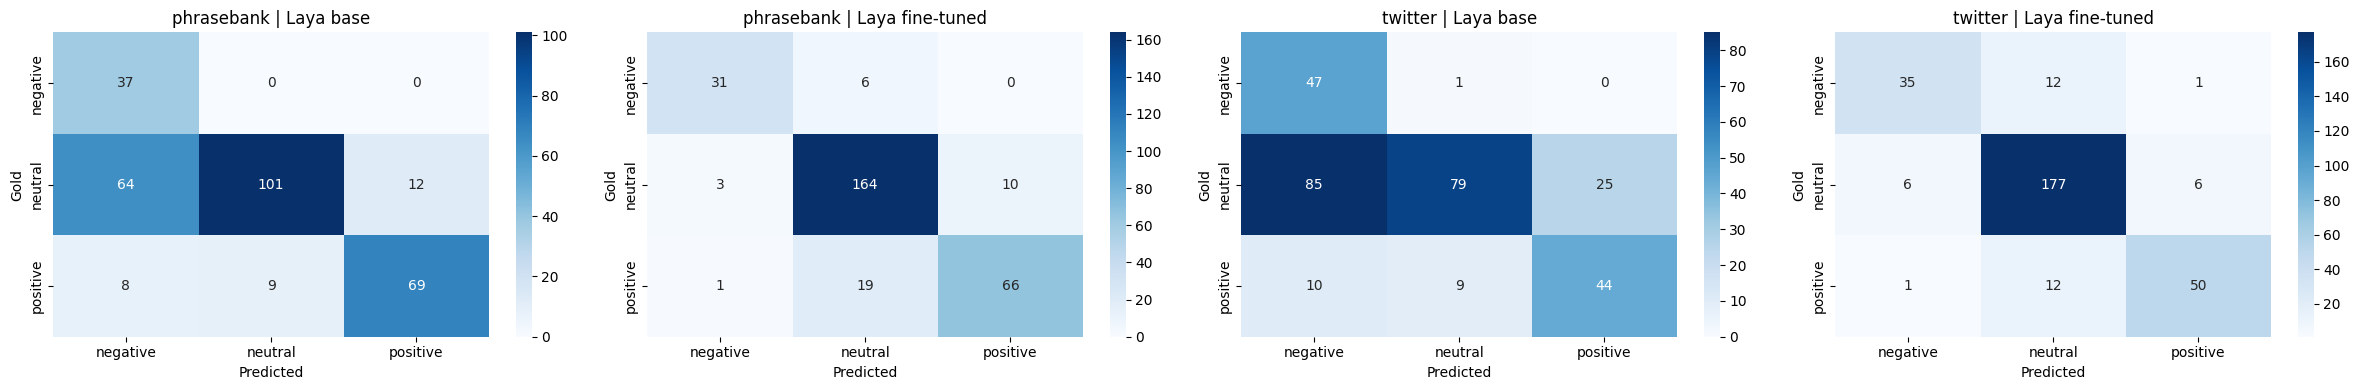

In [10]:
fig,axes=plt.subplots(1,len(classification_outputs),figsize=(6*len(classification_outputs),4))
axes=np.array(axes).reshape(-1)
for ax,((dataset,model_name),df) in zip(axes,classification_outputs.items()):
    cm=confusion_matrix(df.label,df.prediction,labels=LABELS)
    sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=LABELS,yticklabels=LABELS,ax=ax)
    ax.set_title(f"{dataset} | {model_name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Gold")
plt.tight_layout(); plt.show()


## 9. Evaluate held-out FiQA sentiment regression

In [11]:
def sentiment_score_from_answer(answer):
    # Laya score is an expected rubric index; map 0..10 back to the continuous -1..1 scale.
    return float(np.clip(float(answer["score"]),0,10)/5.0-1.0)

fiqa_eval=apply_limit(fiqa_test,REGRESSION_TEST_LIMIT)
regression_outputs={}
for model_name,agent in MODELS.items():
    states=[state_for_fiqa(r) for _,r in fiqa_eval.iterrows()]
    question=regression_question(); values=[]
    for start in tqdm(range(0,len(states),INFERENCE_BATCH_SIZE),desc=f"{model_name} FiQA"):
        out=infer_batch(agent,states[start:start+INFERENCE_BATCH_SIZE],question)
        values.extend([sentiment_score_from_answer(x["answers"]["sentiment"]) for x in out])
    result=fiqa_eval.copy(); result["prediction"]=values; regression_outputs[model_name]=result
    metric_rows.append({"task":"regression","dataset":"FiQA","model":model_name,"n":len(result),
        "mae":mean_absolute_error(result.sentiment_score,result.prediction),
        "rmse":mean_squared_error(result.sentiment_score,result.prediction)**.5,
        "r2":r2_score(result.sentiment_score,result.prediction) if len(result)>1 else np.nan})
display(pd.DataFrame([x for x in metric_rows if x["task"]=="regression"]))


Laya base FiQA:   0%|          | 0/19 [00:00<?, ?it/s]

Laya fine-tuned FiQA:   0%|          | 0/19 [00:00<?, ?it/s]

,task,dataset,model,n,mae,rmse,r2
0,regression,FiQA,Laya base,150,0.504345,0.597497,-2.092106
1,regression,FiQA,Laya fine-tuned,150,0.198450,0.271906,0.359643


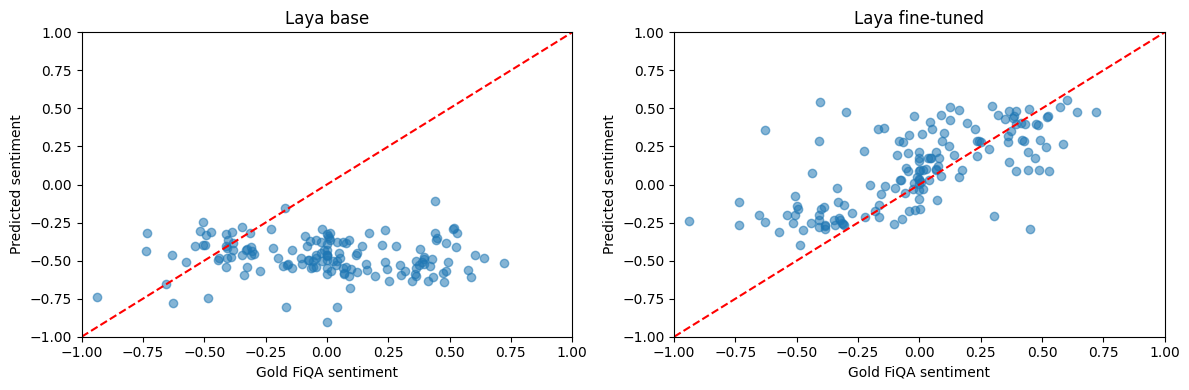

In [12]:
fig,axes=plt.subplots(1,len(regression_outputs),figsize=(6*len(regression_outputs),4))
axes=np.array(axes).reshape(-1)
for ax,(model_name,df) in zip(axes,regression_outputs.items()):
    ax.scatter(df.sentiment_score,df.prediction,alpha=.55); ax.plot([-1,1],[-1,1],"r--")
    ax.set(xlabel="Gold FiQA sentiment",ylabel="Predicted sentiment",title=model_name,xlim=(-1,1),ylim=(-1,1))
plt.tight_layout(); plt.show()


## 10. Evaluate multi-label ticker prediction

In [13]:
def all_ticker_questions():
    return {symbol:ticker_question(symbol) for symbol in TICKERS}

def ticker_inference(agent,frame,model_name,split_name):
    states=[state_for_ticker(r) for _,r in frame.iterrows()]
    q=all_ticker_questions(); answers=[]
    # Keep batches small: each article is evaluated against all ticker questions.
    batch_size=max(1,min(2,INFERENCE_BATCH_SIZE))
    for start in tqdm(range(0,len(states),batch_size),desc=f"{model_name} ticker {split_name}"):
        out=agent.predict_batch(states[start:start+batch_size],q,batch_size=batch_size,sort_by_length=True)
        answers.extend([x["answers"] for x in out])
    rows=[]
    for (_,r),ans in zip(frame.iterrows(),answers):
        rows.append({"_row_id":str(r.name),"gold_tickers":r.gold_tickers,**{t:float(ans[t]["noul"]) for t in TICKERS}})
    return pd.DataFrame(rows)

def ticker_targets(frame):
    return np.array([[int(t in set(x)&set(TICKERS)) for t in TICKERS] for x in frame.gold_tickers],dtype=int)

ticker_metrics_by_model={}; ticker_outputs={}; threshold_curves={}
for model_name,agent in MODELS.items():
    val_probs=ticker_inference(agent,ticker_val,model_name,"validation")
    test_probs=ticker_inference(agent,ticker_test,model_name,"test")
    y_val=ticker_targets(ticker_val); y_test=ticker_targets(ticker_test)
    sweep=[]
    for threshold in np.arange(.05,.951,.025):
        pred=val_probs[TICKERS].to_numpy()>=threshold
        sweep.append((float(threshold),f1_score(y_val,pred,average="macro",zero_division=0)))
    best_threshold=max(sweep,key=lambda x:x[1])[0] if sweep else .5
    y_pred=test_probs[TICKERS].to_numpy()>=best_threshold
    scores={"task":"ticker multilabel","dataset":"Financial News Ticker Linking","model":model_name,"n":len(test_probs),"threshold":best_threshold,
        "micro_precision":precision_score(y_test,y_pred,average="micro",zero_division=0),
        "micro_recall":recall_score(y_test,y_pred,average="micro",zero_division=0),"micro_f1":f1_score(y_test,y_pred,average="micro",zero_division=0),
        "macro_precision":precision_score(y_test,y_pred,average="macro",zero_division=0),
        "macro_recall":recall_score(y_test,y_pred,average="macro",zero_division=0),"macro_f1":f1_score(y_test,y_pred,average="macro",zero_division=0),
        "exact_match":float(np.mean(np.all(y_test==y_pred,axis=1))),"hamming_loss":hamming_loss(y_test,y_pred)}
    try: scores["macro_average_precision"]=average_precision_score(y_test,test_probs[TICKERS].to_numpy(),average="macro")
    except ValueError: scores["macro_average_precision"]=np.nan
    per_ticker=pd.DataFrame({"ticker":TICKERS,"precision":precision_score(y_test,y_pred,average=None,zero_division=0),
        "recall":recall_score(y_test,y_pred,average=None,zero_division=0),"f1":f1_score(y_test,y_pred,average=None,zero_division=0),"support":y_test.sum(0)})
    ticker_metrics_by_model[model_name]=(scores,per_ticker,test_probs,y_pred)
    ticker_outputs[model_name]=test_probs; threshold_curves[model_name]=sweep; metric_rows.append(scores)
display(pd.DataFrame([x[0] for x in ticker_metrics_by_model.values()]))


Laya base ticker validation:   0%|          | 0/25 [00:00<?, ?it/s]

Laya base ticker test:   0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive c

Laya fine-tuned ticker validation:   0%|          | 0/25 [00:00<?, ?it/s]

Laya fine-tuned ticker test:   0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive c

,task,dataset,model,n,threshold,micro_precision,micro_recall,micro_f1,macro_precision,macro_recall,macro_f1,exact_match,hamming_loss,macro_average_precision
0,ticker multilabel,Financial News Ticker Linking,Laya base,100,0.200,0.035785,0.819549,0.068575,0.035915,0.430000,0.062303,0.00,0.604286,0.093151
1,ticker multilabel,Financial News Ticker Linking,Laya fine-tuned,100,0.325,0.500000,0.631579,0.558140,0.210835,0.223954,0.200057,0.24,0.027143,0.236015


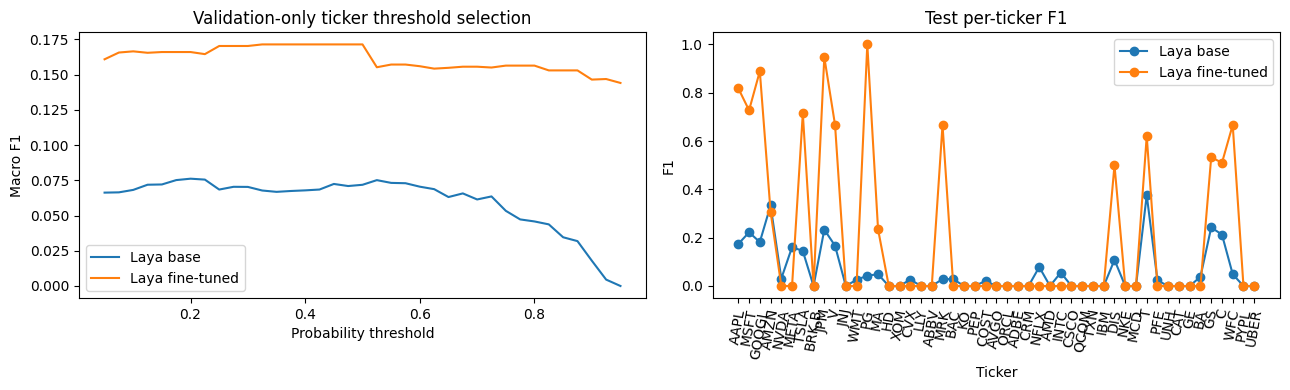

In [14]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for model_name,sweep in threshold_curves.items():
    sdf=pd.DataFrame(sweep,columns=["threshold","validation_macro_f1"])
    axes[0].plot(sdf.threshold,sdf.validation_macro_f1,label=model_name)
axes[0].set(title="Validation-only ticker threshold selection",xlabel="Probability threshold",ylabel="Macro F1"); axes[0].legend()
for model_name,(score,per_ticker,_,_) in ticker_metrics_by_model.items():
    axes[1].plot(per_ticker.ticker,per_ticker.f1,marker="o",label=model_name)
axes[1].tick_params(axis="x",rotation=80); axes[1].set(title="Test per-ticker F1",ylabel="F1",xlabel="Ticker"); axes[1].legend()
plt.tight_layout(); plt.show()


## 11. Save metrics, predictions, and the fine-tuned checkpoint

In [15]:
metrics_df=pd.DataFrame(metric_rows)
metrics_df.to_csv(OUTPUT_DIR/"laya_financial_metrics.csv",index=False)
for (dataset,model_name),df in classification_outputs.items():
    safe=re.sub(r"\W+","_",f"{dataset}_{model_name}".lower())
    df.to_csv(OUTPUT_DIR/f"classification_{safe}.csv",index=False)
for model_name,df in regression_outputs.items():
    safe=re.sub(r"\W+","_",model_name.lower()); df.to_csv(OUTPUT_DIR/f"fiqa_regression_{safe}.csv",index=False)
for model_name,(score,per_ticker,probs,pred) in ticker_metrics_by_model.items():
    safe=re.sub(r"\W+","_",model_name.lower())
    probs=probs.copy(); probs["predicted_tickers"]=["|".join(np.array(TICKERS)[row]) for row in pred]
    probs.to_csv(OUTPUT_DIR/f"ticker_predictions_{safe}.csv",index=False)
    per_ticker.to_csv(OUTPUT_DIR/f"ticker_metrics_{safe}.csv",index=False)
display(metrics_df)
print("Saved benchmark artifacts:",OUTPUT_DIR)
if MODEL_DIR.exists(): print("Fine-tuned Laya checkpoint:",MODEL_DIR)


,task,dataset,model,n,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,mae,rmse,r2,threshold,micro_precision,micro_recall,micro_f1,exact_match,hamming_loss,macro_average_precision
0,classification,phrasebank,Laya base,300,0.690000,0.679010,0.714659,0.703161,0.790982,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,classification,phrasebank,Laya fine-tuned,300,0.870000,0.857367,0.868527,0.873953,0.843944,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,classification,twitter,Laya base,300,0.566667,0.576583,0.577215,0.618769,0.698523,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,classification,twitter,Laya fine-tuned,300,0.873333,0.839601,0.871291,0.863708,0.819775,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,regression,FiQA,Laya base,150,NaN,NaN,NaN,NaN,NaN,0.504345,0.597497,-2.092106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,regression,FiQA,Laya fine-tuned,150,NaN,NaN,NaN,NaN,NaN,0.198450,0.271906,0.359643,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ticker multilabel,Financial News Ticker Linking,Laya base,100,NaN,0.062303,NaN,0.035915,0.430000,NaN,NaN,NaN,0.200,0.035785,0.819549,0.068575,0.00,0.604286,0.093151
7,ticker multilabel,Financial News Ticker Linking,Laya fine-tuned,100,NaN,0.200057,NaN,0.210835,0.223954,NaN,NaN,NaN,0.325,0.500000,0.631579,0.558140,0.24,0.027143,0.236015


Saved benchmark artifacts: /kaggle/working/laya_financial_benchmark
Fine-tuned Laya checkpoint: /kaggle/working/laya_financial_benchmark/laya_financial_finetuned


## Notes on interpretation

- The held-out test results are the final reported scores. Do not use them to choose training epochs, thresholds, or prompts; use validation results for those choices.
- Ticker validation/test measure against the notebook's fixed 49-ticker vocabulary. Articles whose gold tickers are all outside this vocabulary are excluded from this benchmark slice.
- Laya's upstream README describes it as a model to specialize and recommends checking calibration on your own held-out data. This notebook fits temperature values using validation decisions and writes them into the fine-tuned checkpoint configuration.
- The stock Kaggle finetuning recipe uses two T4 GPUs on an independent typed-decisions dataset. This notebook adapts the RLCD training objective to your finance labels and runs on one visible Kaggle GPU with conservative sample limits; it is a project-specific experiment, not a reproduction of the upstream leaderboard result.
